# Story 3 — Are Food Safety Risks Being Overlooked?

**Research question:** Which Chicago ZIPs have relatively *few* recorded sanitation complaints but high observed rates of graded food-inspection failures?

**Definition:** ZIPs with at least 500 graded inspections across 2011–2025. The descriptive “overlooked” flag is **below-median 311 complaint count + above-median food-inspection fail share** among eligible ZIPs—not a claim the city ignored them. Complaint counts are **not normalized** for population or business density.

## Setup and embedded verified aggregates

All figures below are computed from **aggregated results derived from the five user-provided Chicago ZIP archives**, with duplicate request IDs and inspection IDs removed. Figures are embedded in this executed notebook and can be recalculated **without uploading raw ZIPs**. All estimates refer to **2011–2025 complete comparison years**, unless explicitly noted. See the README for methodology. ZIP codes are only proxies for neighborhoods; same ZIP/address is not proof a 311 complaint relates to a specific food establishment.

In [1]:
import json
import builtins
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(9.3,4.6),'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','font.size':10})
BLUE='#28679c'; TEAL='#18877b'; ORANGE='#e19531'; RED='#c95756'; GREY='#7c8791'
def pct(x, n): return 100*x/n if n else np.nan
def style(ax, title, ylabel=None, xlabel=None):
    ax.set_title(title,loc='left',pad=14,fontsize=12)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    ax.grid(axis='y',alpha=.18)
    ax.set_axisbelow(True)
    plt.tight_layout()
def show():
    plt.show()

zip = pd.DataFrame(json.loads(r'''[{"zip":"60601","complaints":292,"graded":4142,"fails":556,"fail_pct":13.4235,"group":"Low reports · low fail"},{"zip":"60602","complaints":207,"graded":1763,"fails":289,"fail_pct":16.3925,"group":"Low reports · low fail"},{"zip":"60603","complaints":145,"graded":2290,"fails":364,"fail_pct":15.8952,"group":"Low reports · low fail"},{"zip":"60604","complaints":98,"graded":1504,"fails":235,"fail_pct":15.625,"group":"Low reports · low fail"},{"zip":"60605","complaints":680,"graded":3843,"fails":827,"fail_pct":21.5196,"group":"Low reports · low fail"},{"zip":"60606","complaints":191,"graded":3799,"fails":525,"fail_pct":13.8194,"group":"Low reports · low fail"},{"zip":"60607","complaints":1591,"graded":6967,"fails":1516,"fail_pct":21.7597,"group":"Low reports · low fail"},{"zip":"60608","complaints":5909,"graded":7450,"fails":1751,"fail_pct":23.5034,"group":"High reports · high fail"},{"zip":"60609","complaints":6146,"graded":5058,"fails":1104,"fail_pct":21.8268,"group":"High reports · low fail"},{"zip":"60610","complaints":2053,"graded":4907,"fails":959,"fail_pct":19.5435,"group":"Low reports · low fail"},{"zip":"60611","complaints":565,"graded":8097,"fails":1401,"fail_pct":17.3027,"group":"Low reports · low fail"},{"zip":"60612","complaints":5215,"graded":4008,"fails":889,"fail_pct":22.1806,"group":"High reports · low fail"},{"zip":"60613","complaints":2463,"graded":5408,"fails":1081,"fail_pct":19.9889,"group":"Low reports · low fail"},{"zip":"60614","complaints":8139,"graded":8968,"fails":2085,"fail_pct":23.2493,"group":"High reports · high fail"},{"zip":"60615","complaints":2345,"graded":2929,"fails":772,"fail_pct":26.3571,"group":"Low reports · high fail"},{"zip":"60616","complaints":2823,"graded":6449,"fails":1515,"fail_pct":23.492,"group":"Low reports · high fail"},{"zip":"60617","complaints":9633,"graded":4859,"fails":1226,"fail_pct":25.2315,"group":"High reports · high fail"},{"zip":"60618","complaints":8141,"graded":7396,"fails":1381,"fail_pct":18.6723,"group":"High reports · low fail"},{"zip":"60619","complaints":11265,"graded":4799,"fails":1446,"fail_pct":30.1313,"group":"High reports · high fail"},{"zip":"60620","complaints":11695,"graded":4658,"fails":1346,"fail_pct":28.8965,"group":"High reports · high fail"},{"zip":"60621","complaints":5767,"graded":2074,"fails":581,"fail_pct":28.0135,"group":"High reports · high fail"},{"zip":"60622","complaints":5736,"graded":7402,"fails":1700,"fail_pct":22.9668,"group":"High reports · high fail"},{"zip":"60623","complaints":6783,"graded":5551,"fails":1469,"fail_pct":26.4637,"group":"High reports · high fail"},{"zip":"60624","complaints":5772,"graded":2486,"fails":648,"fail_pct":26.066,"group":"High reports · high fail"},{"zip":"60625","complaints":4709,"graded":6717,"fails":1628,"fail_pct":24.237,"group":"High reports · high fail"},{"zip":"60626","complaints":2560,"graded":3795,"fails":946,"fail_pct":24.9275,"group":"Low reports · high fail"},{"zip":"60628","complaints":10875,"graded":4360,"fails":1271,"fail_pct":29.1514,"group":"High reports · high fail"},{"zip":"60629","complaints":7853,"graded":4690,"fails":1013,"fail_pct":21.5991,"group":"High reports · low fail"},{"zip":"60630","complaints":3599,"graded":3287,"fails":706,"fail_pct":21.4786,"group":"Low reports · low fail"},{"zip":"60631","complaints":1233,"graded":1833,"fails":363,"fail_pct":19.8036,"group":"Low reports · low fail"},{"zip":"60632","complaints":7327,"graded":5762,"fails":1252,"fail_pct":21.7286,"group":"High reports · low fail"},{"zip":"60634","complaints":4659,"graded":4708,"fails":884,"fail_pct":18.7766,"group":"High reports · low fail"},{"zip":"60636","complaints":7729,"graded":2710,"fails":760,"fail_pct":28.0443,"group":"High reports · high fail"},{"zip":"60637","complaints":5367,"graded":2943,"fails":780,"fail_pct":26.5036,"group":"High reports · high fail"},{"zip":"60638","complaints":3476,"graded":3363,"fails":508,"fail_pct":15.1056,"group":"Low reports · low fail"},{"zip":"60639","complaints":6450,"graded":6504,"fails":1762,"fail_pct":27.091,"group":"High reports · high fail"},{"zip":"60640","complaints":3505,"graded":6639,"fails":1543,"fail_pct":23.2415,"group":"Low reports · high fail"},{"zip":"60641","complaints":5067,"graded":4226,"fails":838,"fail_pct":19.8296,"group":"High reports · low fail"},{"zip":"60642","complaints":2483,"graded":3047,"fails":624,"fail_pct":20.4792,"group":"Low reports · low fail"},{"zip":"60643","complaints":5331,"graded":3533,"fails":795,"fail_pct":22.5021,"group":"High reports · high fail"},{"zip":"60644","complaints":5970,"graded":2906,"fails":791,"fail_pct":27.2195,"group":"High reports · high fail"},{"zip":"60645","complaints":2999,"graded":1731,"fails":422,"fail_pct":24.379,"group":"Low reports · high fail"},{"zip":"60646","complaints":1741,"graded":1742,"fails":321,"fail_pct":18.4271,"group":"Low reports · low fail"},{"zip":"60647","complaints":9073,"graded":8792,"fails":2082,"fail_pct":23.6806,"group":"High reports · high fail"},{"zip":"60649","complaints":5951,"graded":2817,"fails":659,"fail_pct":23.3937,"group":"High reports · high fail"},{"zip":"60651","complaints":7530,"graded":3304,"fails":942,"fail_pct":28.5109,"group":"High reports · high fail"},{"zip":"60652","complaints":3747,"graded":2149,"fails":375,"fail_pct":17.45,"group":"High reports · low fail"},{"zip":"60653","complaints":2588,"graded":2115,"fails":482,"fail_pct":22.7896,"group":"Low reports · high fail"},{"zip":"60654","complaints":625,"graded":5630,"fails":1005,"fail_pct":17.8508,"group":"Low reports · low fail"},{"zip":"60655","complaints":1024,"graded":1089,"fails":193,"fail_pct":17.7227,"group":"Low reports · low fail"},{"zip":"60656","complaints":1055,"graded":973,"fails":204,"fail_pct":20.9661,"group":"Low reports · low fail"},{"zip":"60657","complaints":4941,"graded":7982,"fails":1747,"fail_pct":21.8867,"group":"High reports · low fail"},{"zip":"60659","complaints":3616,"graded":4893,"fails":1215,"fail_pct":24.8314,"group":"High reports · high fail"},{"zip":"60660","complaints":1760,"graded":3738,"fails":924,"fail_pct":24.7191,"group":"Low reports · high fail"},{"zip":"60661","complaints":254,"graded":3303,"fails":547,"fail_pct":16.5607,"group":"Low reports · low fail"},{"zip":"60666","complaints":11,"graded":3504,"fails":423,"fail_pct":12.0719,"group":"Low reports · low fail"},{"zip":"60707","complaints":1430,"graded":1314,"fails":301,"fail_pct":22.9072,"group":"Low reports · high fail"}]'''))
quad = pd.DataFrame(json.loads(r'''[{"group":"High reports · high fail","zips":20,"graded":97726,"fails":24937,"fail_pct":25.517262550396005},{"group":"High reports · low fail","zips":9,"graded":45979,"fails":9483,"fail_pct":20.624632984623414},{"group":"Low reports · high fail","zips":8,"graded":28710,"fails":6905,"fail_pct":24.05085336119819},{"group":"Low reports · low fail","zips":20,"graded":70491,"fails":12647,"fail_pct":17.941297470599082}]'''))
flagged = pd.DataFrame(json.loads(r'''[{"zip":"60615","complaints":2345,"graded":2929,"fails":772,"fail_pct":26.3571},{"zip":"60626","complaints":2560,"graded":3795,"fails":946,"fail_pct":24.9275},{"zip":"60660","complaints":1760,"graded":3738,"fails":924,"fail_pct":24.7191},{"zip":"60645","complaints":2999,"graded":1731,"fails":422,"fail_pct":24.379},{"zip":"60616","complaints":2823,"graded":6449,"fails":1515,"fail_pct":23.492},{"zip":"60640","complaints":3505,"graded":6639,"fails":1543,"fail_pct":23.2415},{"zip":"60707","complaints":1430,"graded":1314,"fails":301,"fail_pct":22.9072},{"zip":"60653","complaints":2588,"graded":2115,"fails":482,"fail_pct":22.7896}]'''))
annualflags = pd.DataFrame(json.loads(r'''[{"year":2011,"eligible_zip_years":57,"low_reports_high_fails":11},{"year":2012,"eligible_zip_years":57,"low_reports_high_fails":11},{"year":2013,"eligible_zip_years":57,"low_reports_high_fails":10},{"year":2014,"eligible_zip_years":57,"low_reports_high_fails":9},{"year":2015,"eligible_zip_years":57,"low_reports_high_fails":9},{"year":2016,"eligible_zip_years":57,"low_reports_high_fails":10},{"year":2017,"eligible_zip_years":57,"low_reports_high_fails":11},{"year":2018,"eligible_zip_years":55,"low_reports_high_fails":12},{"year":2019,"eligible_zip_years":57,"low_reports_high_fails":11},{"year":2020,"eligible_zip_years":57,"low_reports_high_fails":9},{"year":2021,"eligible_zip_years":56,"low_reports_high_fails":10},{"year":2022,"eligible_zip_years":56,"low_reports_high_fails":12},{"year":2023,"eligible_zip_years":57,"low_reports_high_fails":6},{"year":2024,"eligible_zip_years":57,"low_reports_high_fails":11},{"year":2025,"eligible_zip_years":57,"low_reports_high_fails":12}]'''))
sensitivity = pd.DataFrame(json.loads(r'''[{"definition":"Median split","flagged_zips":8,"graded":28710,"fails":6905},{"definition":"Lower 40% / upper 60%","flagged_zips":3,"graded":10462,"fails":2642},{"definition":"Bottom/top quartile","flagged_zips":0,"graded":0,"fails":0}]'''))
highfail_missed = pd.DataFrame(json.loads(r'''[{"group":"High failure & high complaints","zips":9},{"group":"High failure, NOT high complaints","zips":6}]'''))
matches = pd.DataFrame(json.loads(r'''[{"matched":false,"address_years":139903,"inspections":271611,"graded":231639,"fails":51174,"fail_pct":22.092134744149302},{"matched":true,"address_years":6065,"inspections":14169,"graded":11957,"fails":2986,"fail_pct":24.97281926904742}]'''))

MEDIAN_COMPLAINTS = 3616.0
MEDIAN_FAIL_PCT = 22.1806


### Chart 1 | Find the mismatch quadrants

**Question:** Which ZIPs fall into the low-reporting / high-failure quadrant?

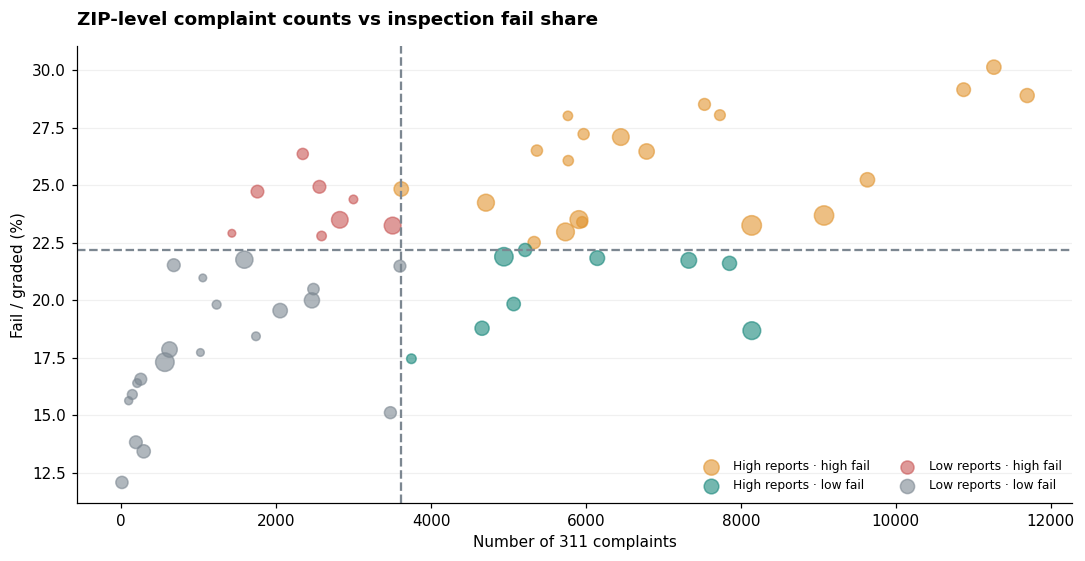

In [2]:
fig,ax=plt.subplots(figsize=(10,5.2));palette={'Low reports · high fail':RED,'Low reports · low fail':GREY,'High reports · high fail':ORANGE,'High reports · low fail':TEAL}
for grp,g in zip.groupby('group'):
 ax.scatter(g.complaints,g.fail_pct,s=np.clip(g.graded/55,25,180),alpha=.6,color=palette[grp],label=grp)
ax.axvline(MEDIAN_COMPLAINTS,color=GREY,ls='--');ax.axhline(MEDIAN_FAIL_PCT,color=GREY,ls='--');ax.legend(fontsize=8,frameon=False,ncol=2)
style(ax,'ZIP-level complaint counts vs inspection fail share','Fail / graded (%)','Number of 311 complaints');show()

**Interpretation:** The red quadrant identifies a *screening hypothesis*, not a proven safety problem. The thresholds are relative to other Chicago ZIPs rather than regulatory standards.

### Chart 2 | Candidate underreported ZIPs

**Question:** Which ZIPs have the highest observed failure rates among low-complaint ZIPs?

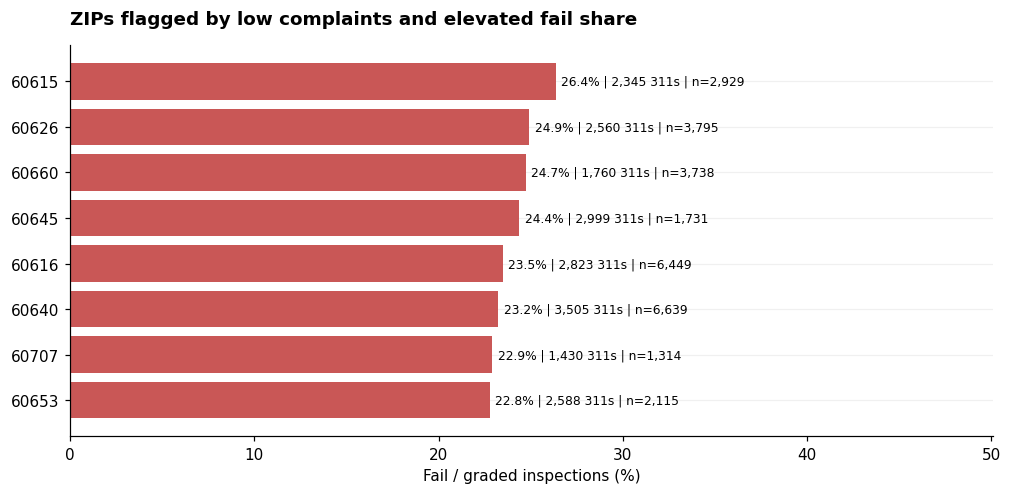

In [3]:
d=flagged.head(10).sort_values('fail_pct');fig,ax=plt.subplots();bars=ax.barh(d.zip,d.fail_pct,color=RED)
for b,r in builtins.zip(bars,d.itertuples()):ax.text(b.get_width()+.3,b.get_y()+b.get_height()/2,f'{r.fail_pct:.1f}% | {r.complaints:,} 311s | n={r.graded:,}',fontsize=8,va='center')
ax.set_xlim(0,d.fail_pct.max()*1.9);style(ax,'ZIPs flagged by low complaints and elevated fail share',xlabel='Fail / graded inspections (%)');show()

**Interpretation:** ZIP rankings show where investigation may be useful, but low complaint totals may reflect fewer residents, fewer sites, or different reporting behavior.

### Chart 3 | How many ZIPs are in each group?

**Question:** How frequently do the four complaint/failure combinations occur?

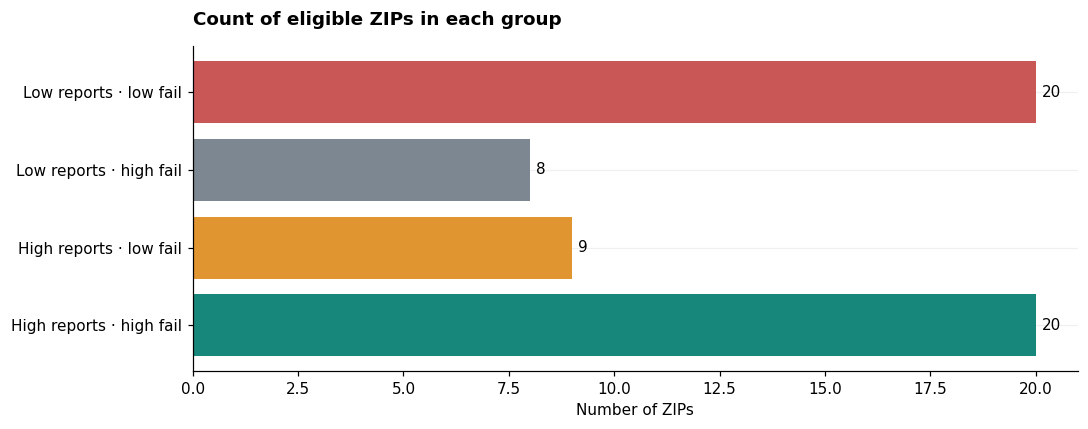

In [4]:
fig,ax=plt.subplots(figsize=(10,4));colors=[TEAL,ORANGE,GREY,RED];d=quad.sort_values('group');b=ax.barh(d.group,d.zips,color=colors)
for p,r in builtins.zip(b,d.itertuples()):ax.text(p.get_width()+.15,p.get_y()+p.get_height()/2,str(r.zips),va='center')
style(ax,'Count of eligible ZIPs in each group',xlabel='Number of ZIPs');show()

**Interpretation:** The groups describe administrative ZIP codes, not individual establishments. A 311-only prioritization rule could miss some ZIPs with elevated inspection failures.

### Chart 4 | Inspection data without a same-year address match

**Question:** How many graded inspections are at addresses with no exact same-year 311 sanitation match?

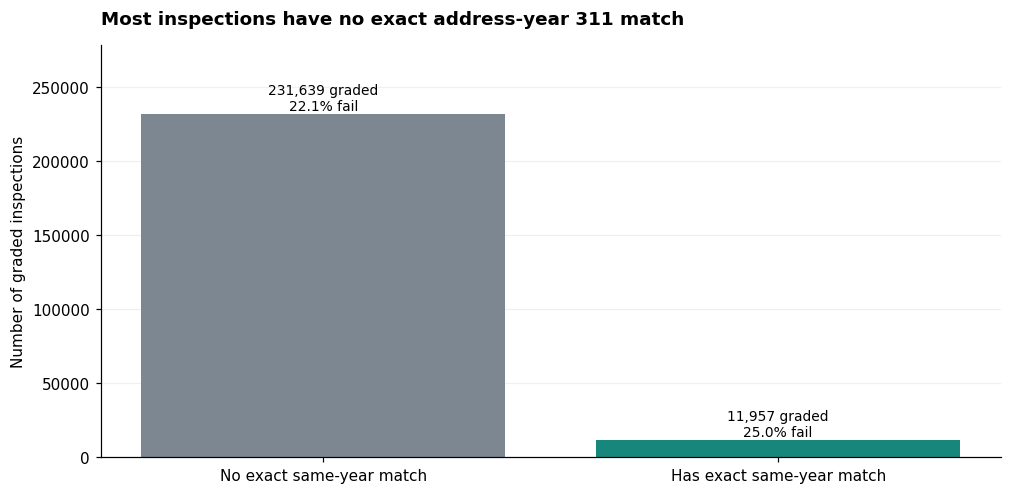

In [5]:
d=matches.copy();d['label']=d.matched.map({False:'No exact same-year match',True:'Has exact same-year match'})
fig,ax=plt.subplots();bars=ax.bar(d.label,d.graded,color=[GREY,TEAL]);
for b,r in builtins.zip(bars,d.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+2500,f'{r.graded:,} graded\n{r.fail_pct:.1f}% fail',ha='center',fontsize=9)
ax.set_ylim(0,max(d.graded)*1.2);style(ax,'Most inspections have no exact address-year 311 match','Number of graded inspections');show()

**Interpretation:** No match does **not** mean no sanitation hazard. The datasets may use different address formats, 311 requests are not necessarily food-related, and some establishment issues are not publicly reported.

### Chart 5 | Annual prevalence of mismatch flags

**Question:** Is the low-complaint/high-failure pattern visible across different years?

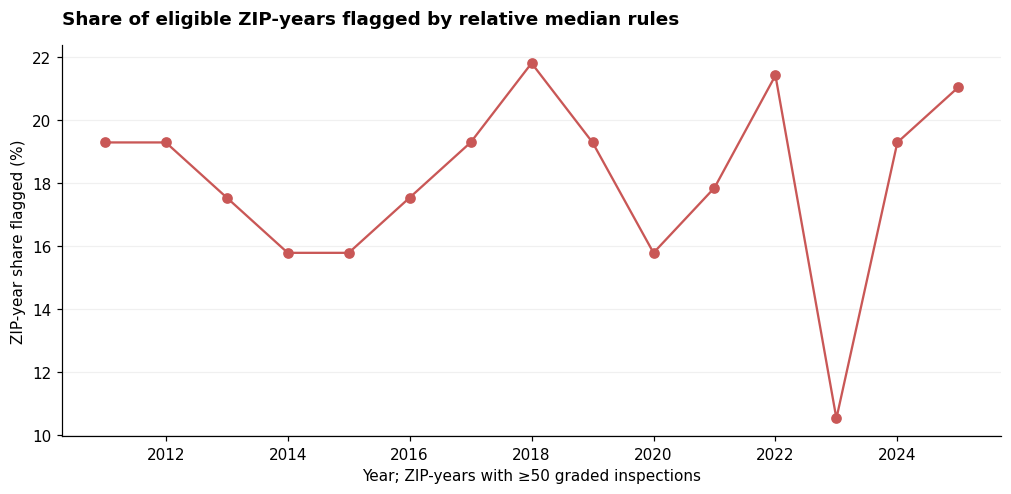

In [6]:
d=annualflags;fig,ax=plt.subplots();ax.plot(d.year,100*d.low_reports_high_fails/d.eligible_zip_years,marker='o',color=RED)
style(ax,'Share of eligible ZIP-years flagged by relative median rules','ZIP-year share flagged (%)','Year; ZIP-years with ≥50 graded inspections');show()

**Interpretation:** For each year the thresholds are recomputed using that year’s eligible ZIPs. This tests whether the pattern recurs, not whether the **same** ZIPs remain persistently underserved.

### Chart 6 | Test the screening threshold

**Question:** Does the candidate list shrink under more stringent threshold definitions?

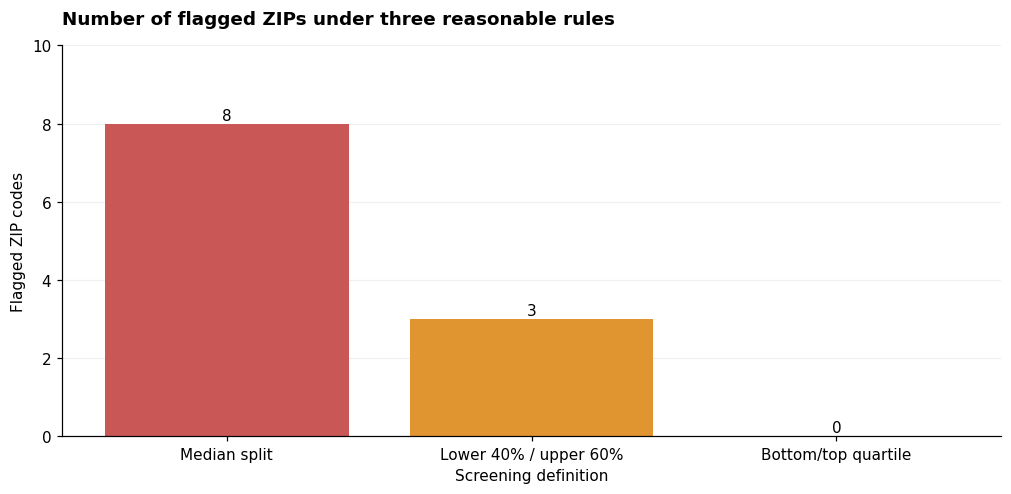

High-failure ZIPs NOT captured by top-quartile 311 complaint volume:
                            group  zips
   High failure & high complaints     9
High failure, NOT high complaints     6


In [7]:
fig,ax=plt.subplots();bars=ax.bar(sensitivity.definition,sensitivity.flagged_zips,color=[RED,ORANGE,TEAL])
for p,r in builtins.zip(bars,sensitivity.itertuples()):ax.text(p.get_x()+p.get_width()/2,p.get_height()+.1,str(r.flagged_zips),ha='center')
ax.set_ylim(0,max(sensitivity.flagged_zips)*1.25);style(ax,'Number of flagged ZIPs under three reasonable rules','Flagged ZIP codes','Screening definition');show()
print('High-failure ZIPs NOT captured by top-quartile 311 complaint volume:')
print(highfail_missed.to_string(index=False))

**Interpretation:** If a flagged list changes sharply with thresholds, it is not a robust basis for allocation decisions by itself. Combine flags with inspection history, establishment counts, and other verified signals.

## Discussion and responsible claims

**Best answer:** Low 311 reporting is not evidence of low food-safety risk. Some ZIPs with comparatively few complaints still show high inspection failure shares; these are candidates for further checks, not proof that city inspectors overlooked specific businesses. Avoid presenting unadjusted count ranks as per-capita neighborhood risk.

## Key Findings and Business Implications

### Executive takeaway
**Low 311 complaint volume does not guarantee low observed food-inspection failure rates.** The flagged ZIP codes are places to *check further*, not proof of overlooked hazards, underreporting, or city failure.

### Four evidence-backed findings

1. **Some low-complaint ZIPs have high failure shares (Charts 1–3).** Of **57 ZIP codes** with at least **500** graded inspections in 2011–2025, **8** fell below the city sample's median **3,616** complaints while exceeding its median **22.2%** failure rate. These are *relative screening rules*, not health department standards.
2. **Examples illustrate the mismatch (Chart 2).** ZIP **60615** had **2,345** sanitation requests and a **26.4%** failure rate (**n=2,929** graded inspections). ZIP **60626** had **2,560** requests and **24.9%** failures (**n=3,795**).
3. **Most inspection address-years lack an exact same-year 311 match (Chart 4).** Only **6,065** of **145,968** inspected address-years had a standardized same-address, same-year 311 co-occurrence (**4.16%**). The absence of a match could mean no report, different address formats, or a report about an unrelated issue; **it does not prove safety**.
4. **The candidate list is sensitive to thresholds (Chart 6).** The basic median-split definition flags **8** ZIPs; a lower-40%/upper-60% threshold flags **3**, and bottom/top quartiles flag **0**. A screening rule this sensitive should not drive resource allocation alone.

### Business / public-service implications

- **CDPH:** use graded inspection failure rates alongside complaint information when screening neighborhoods, so low volumes of public reports do not hide areas worth auditing.
- **311 service design:** consider whether awareness, language accessibility, internet access, or reporting practices affect observed reporting volume; these are hypotheses to evaluate, not established explanations here.
- **Facility managers:** prioritize their own inspection and violation histories, not broad ZIP-level complaint counts, when planning preventive training.

### Recommended next steps

1. Recalculate complaint rates per establishment or resident where a valid denominator exists; add restaurant inventory and inspector coverage to the comparisons.
2. Re-run the flags with multiple thresholds and uncertainty intervals, and check whether a ZIP is flagged consistently across years instead of only in aggregate.
3. Review individual inspected facilities and complaint narratives before discussing specific businesses as “overlooked.”

### Limits and responsible conclusion

The word **“overlooked” is a research hypothesis**, not an observed outcome. Relative ZIP rankings cannot establish individual food-safety risks, and a low complaint count may reflect fewer potential reporters or fewer licensed food establishments. The finding supports **multi-source screening**, not claims that inspectors neglected any ZIP.

**Source of values:** `eligible_zip_summary.csv`, `join_coverage.csv`, and `story3_flag_sensitivity.csv`, with definitions embedded in the notebook.
